# Task 2: Predictive Linear Regression Model Pipeline

## Objective
Build a supervised regression model to predict house prices (a continuous value)
using the California Housing dataset, with preprocessing (feature scaling,
mean imputation, categorical encoding) and a regularized Ridge regression model.
Evaluate using R² and RMSE.

## Import Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_squared_error

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## Load Dataset

In [6]:
df = pd.read_csv('housing.csv')

print("Dataset loaded successfully")
print("Shape (rows, columns):", df.shape)
df.head()

Dataset loaded successfully
Shape (rows, columns): (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Data Exploration

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## Missing values check

In [9]:

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


# Categorical column check

In [10]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## EDA

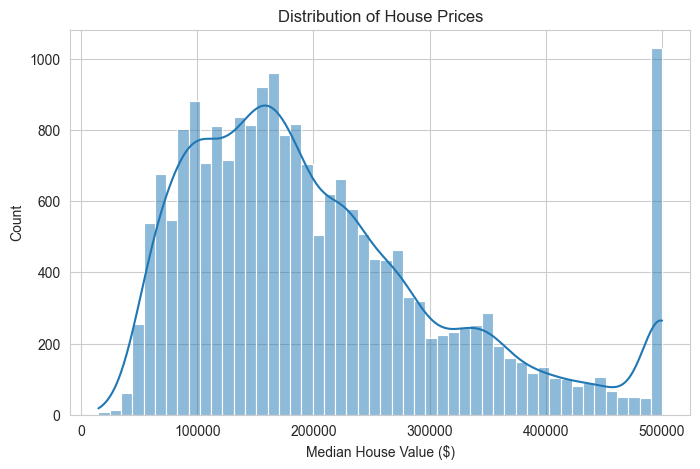

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Median House Value ($)')
plt.show()

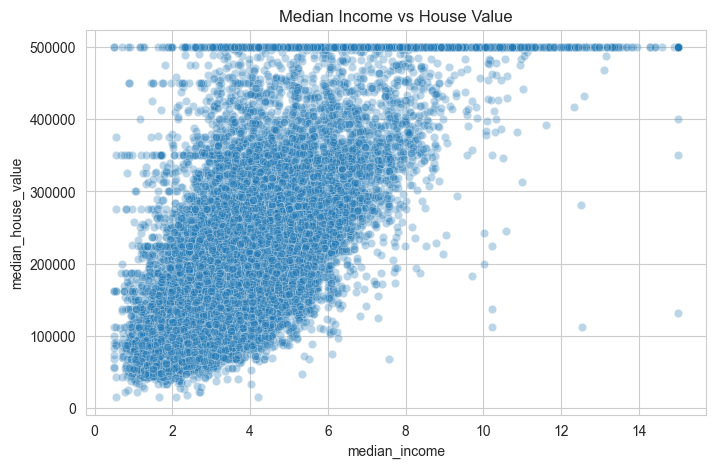

In [12]:
# 2. Income vs house price 
plt.figure(figsize=(8,5))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.3)
plt.title('Median Income vs House Value')
plt.show()

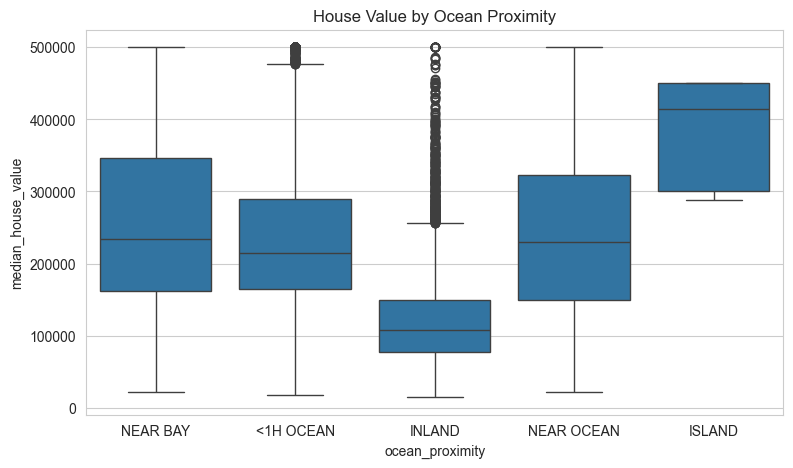

In [13]:
# 3. Price by ocean proximity
plt.figure(figsize=(9,5))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df)
plt.title('House Value by Ocean Proximity')
plt.show()

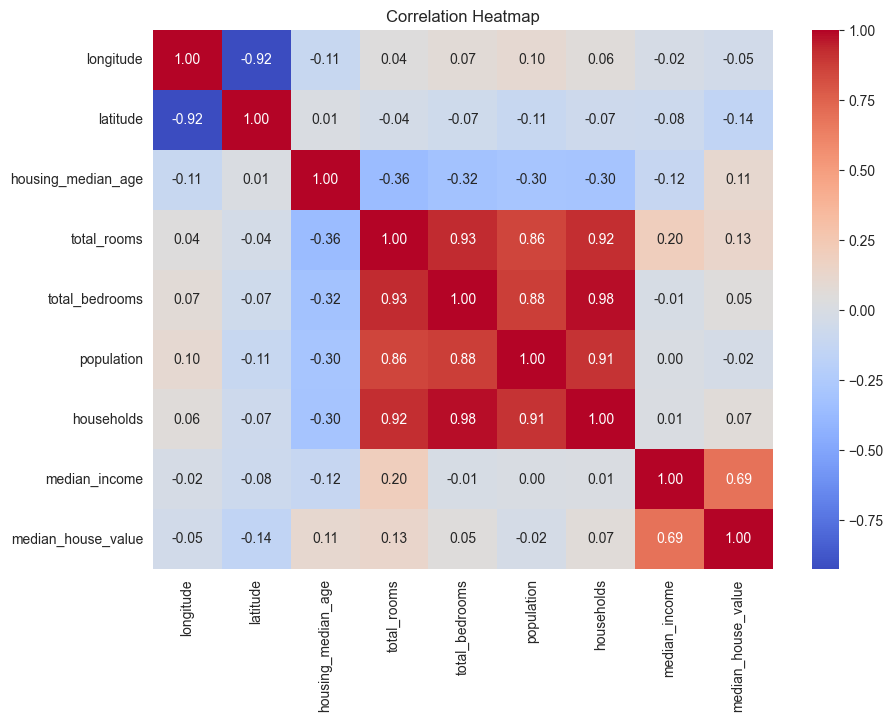

In [14]:
# 4. Correlation heatmap
plt.figure(figsize=(10,7))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## Features (X) aur Target (y) alag karein

In [15]:
X = df.drop('median_house_value', axis=1)   # inputs
y = df['median_house_value']                # which is to be predicted 

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = ['ocean_proximity']

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical columns: ['ocean_proximity']


## Train/Test Split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (16512, 9)
Test shape: (4128, 9)


## Preprocessing

In [17]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),   # 1. Mean Imputation
    ('scaler', StandardScaler())                   # 2. Feature Scaling
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)   # 3. Categorical Encoding
])

print("Preprocessing pipeline created")

Preprocessing pipeline created


## Ridge Regression model train 

In [18]:
ridge_model = Pipeline([
    ('preprocessing', preprocessor),
    ('model', Ridge(alpha=1.0))      # regularized linear regression
])

ridge_model.fit(X_train, y_train)
print("Ridge model trained successfully")

Ridge model trained successfully


## Evaluation aur Metrics Logging (R² aur RMSE)

In [19]:
results = []

models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1.0),
    'Ridge (alpha=10)': Ridge(alpha=10.0)
}

for name, model in models.items():
    pipe = Pipeline([('preprocessing', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({'Model': name, 'R2': round(r2, 4), 'RMSE': round(rmse, 2)})
    print(f"{name}:  R² = {r2:.4f}  |  RMSE = {rmse:,.0f}")

# to save Metrics in file
metrics_df = pd.DataFrame(results)
metrics_df.to_csv('metrics_log.csv', index=False)
print("\nMetrics saved to metrics_log.csv")
metrics_df

Linear Regression:  R² = 0.6257  |  RMSE = 70,031
Ridge (alpha=1):  R² = 0.6257  |  RMSE = 70,038
Ridge (alpha=10):  R² = 0.6255  |  RMSE = 70,056

Metrics saved to metrics_log.csv


,Model,R2,RMSE
0,Linear Regression,0.6257,70031.49
1,Ridge (alpha=1),0.6257,70038.41
2,Ridge (alpha=10),0.6255,70055.89


## Actual vs Predicted chart

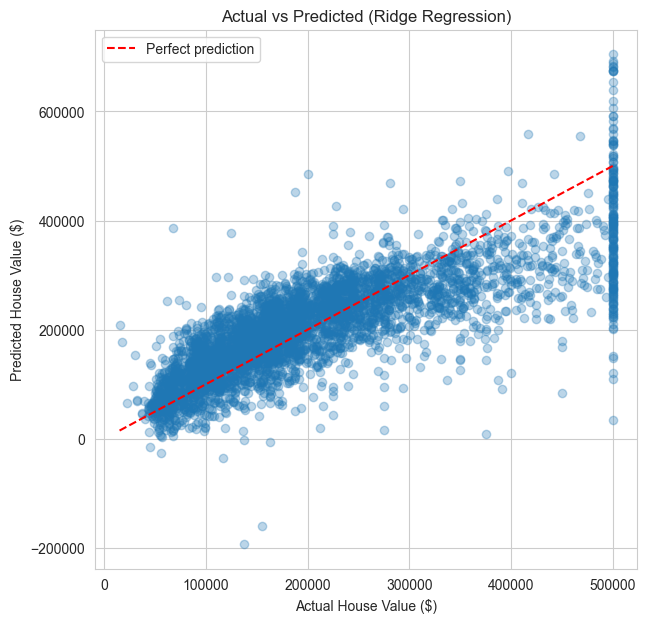

In [20]:
y_pred = ridge_model.predict(X_test)

plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Perfect prediction')
plt.xlabel('Actual House Value ($)')
plt.ylabel('Predicted House Value ($)')
plt.title('Actual vs Predicted (Ridge Regression)')
plt.legend()
plt.show()

## Conclusion

- Built a complete regression pipeline: mean imputation for missing values
  (total_bedrooms), standard scaling for numerical features, and one-hot
  encoding for the categorical feature (ocean_proximity).
- Trained Linear Regression and regularized Ridge Regression models.
- Ridge Regression achieved R² ≈ 0.63 and RMSE ≈ $70,000, meaning the model
  explains about 63% of the variation in house prices.
- Ridge and Linear Regression performed almost the same because the dataset is
  large (20,640 rows) with few features, so overfitting risk was low.
- Median income is the strongest predictor of house value.
- Future improvement: try non-linear models such as Random Forest or XGBoost
  for higher accuracy.